# Group Model Comparison Notebook

### Models Compared
| Student ID | Name | Algorithm |
|------------|------|-----------|
| IT25102115 | Malka H. A. G. | Logistic Regression |
| IT25101986 | Thashmina P. G. D. | SVM |
| IT25101160 | Rukmalgoda R.D.D. | Decision Tree |
| IT25102054 | Dinali L. D. G. N. | KNN |
| IT25102047 | Palihakkara P. J. | Random Forest |
| IT25100170 | Thanthrige P.D.I. | MLP (Keras) |


## 1. Setup & Load Preprocessed Data


In [ ]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

# Keras / TensorFlow for MLP
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers

np.random.seed(42)
tf.random.set_seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print("Libraries loaded. TensorFlow:", tf.__version__)

Libraries loaded. TensorFlow: 2.21.0


In [ ]:
# Mount Google Drive and load preprocessed data
from google.colab import drive
drive.mount('/content/drive')

# >>> UPDATE THIS PATH if your Drive folder structure is different <<<
DATA_PATH = '/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/results/outputs/processed_breast_cancer.csv'

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df['Class'].value_counts())
df.head()

Mounted at /content/drive
Dataset shape: (699, 20)

Class distribution:
Class
0    458
1    241
Name: count, dtype: int64


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


In [ ]:
# Prepare features and target
df = df.drop(columns=['Sample_code_number'], errors='ignore')

feature_cols_orig = [
    'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
    'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
    'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses'
]
feature_cols_scaled = [c + '_scaled' for c in feature_cols_orig]

X_orig   = df[feature_cols_orig].values
X_scaled = df[feature_cols_scaled].values.astype('float32')
y        = df['Class'].values

# Stratified 80/20 split (same for all models)
X_train_o, X_test_o, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)
X_train_s, X_test_s, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print("Train size:", len(y_train), "| Test size:", len(y_test))
print("Train class dist:", np.bincount(y_train))
print("Test class dist :", np.bincount(y_test))

Train size: 559 | Test size: 140
Train class dist: [366 193]
Test class dist : [92 48]


## 2. Train All 6 Optimum Models

We use the **best configuration** typically found by each member (scaled features where beneficial, reasonable hyperparameters).


In [ ]:
def get_metrics(y_true, y_pred, y_prob, name):
    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall':    recall_score(y_true, y_pred, zero_division=0),
        'F1-Score':  f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC':   roc_auc_score(y_true, y_prob)
    }

results = []
predictions = {}   # store y_pred and y_prob for later plots
print("Training all models...\n")

Training all models...



In [ ]:
# ------------------------------------------------------------
# 1. Logistic Regression (Malka - IT25102115)
# ------------------------------------------------------------
lr = LogisticRegression(C=0.1, penalty='l2', solver='lbfgs', max_iter=2000, random_state=42)
lr.fit(X_train_s, y_train)
y_pred = lr.predict(X_test_s)
y_prob = lr.predict_proba(X_test_s)[:, 1]
results.append(get_metrics(y_test, y_pred, y_prob, 'Logistic Regression\n(Malka)'))
predictions['Logistic Regression'] = (y_pred, y_prob)
print("1/6 Logistic Regression done")

1/6 Logistic Regression done


In [ ]:
# ------------------------------------------------------------
# 2. SVM (Thashmina - IT25101986)
# ------------------------------------------------------------
svm = SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)
svm.fit(X_train_s, y_train)
y_pred = svm.predict(X_test_s)
y_prob = svm.predict_proba(X_test_s)[:, 1]
results.append(get_metrics(y_test, y_pred, y_prob, 'SVM (RBF)\n(Thashmina)'))
predictions['SVM'] = (y_pred, y_prob)
print("2/6 SVM done")

2/6 SVM done


In [ ]:
# ------------------------------------------------------------
# 3. Decision Tree (Rukmalgoda - IT25101160)
# ------------------------------------------------------------
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, min_samples_split=10,
                            criterion='gini', random_state=42)
dt.fit(X_train_o, y_train)   # trees prefer original features
y_pred = dt.predict(X_test_o)
y_prob = dt.predict_proba(X_test_o)[:, 1]
results.append(get_metrics(y_test, y_pred, y_prob, 'Decision Tree\n(Rukmalgoda)'))
predictions['Decision Tree'] = (y_pred, y_prob)
print("3/6 Decision Tree done")

3/6 Decision Tree done


In [ ]:
# ------------------------------------------------------------
# 4. KNN (Dinali - IT25102054)
# ------------------------------------------------------------
knn = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='euclidean')
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)
y_prob = knn.predict_proba(X_test_s)[:, 1]
results.append(get_metrics(y_test, y_pred, y_prob, 'KNN\n(Dinali)'))
predictions['KNN'] = (y_pred, y_prob)
print("4/6 KNN done")

4/6 KNN done


In [ ]:
# ------------------------------------------------------------
# 5. Random Forest (Palihakkara - IT25102047)
# ------------------------------------------------------------
rf = RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=3,
                            class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train_o, y_train)
y_pred = rf.predict(X_test_o)
y_prob = rf.predict_proba(X_test_o)[:, 1]
results.append(get_metrics(y_test, y_pred, y_prob, 'Random Forest\n(Palihakkara)'))
predictions['Random Forest'] = (y_pred, y_prob)
print("5/6 Random Forest done")

5/6 Random Forest done


In [ ]:
# ------------------------------------------------------------
# 6. MLP - Keras (Thanthrige - IT25100170)
# ------------------------------------------------------------
# Small validation split from training data
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_s, y_train, test_size=0.2, random_state=42, stratify=y_train
)

mlp = keras.Sequential([
    layers.Input(shape=(9,)),
    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.25),
    layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.25),
    layers.Dense(1, activation='sigmoid')
], name='MLP_Group')

mlp.compile(optimizer=keras.optimizers.Adam(0.001),
            loss='binary_crossentropy',
            metrics=['accuracy'])

early = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

# Class weights
n0, n1 = np.bincount(y_tr.astype(int))
cw = {0: 1.0, 1: n0 / n1}

mlp.fit(X_tr, y_tr, validation_data=(X_val, y_val),
        epochs=150, batch_size=32, class_weight=cw,
        callbacks=[early], verbose=0)

y_prob = mlp.predict(X_test_s, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
results.append(get_metrics(y_test, y_pred, y_prob, 'MLP (Keras)\n(Thanthrige)'))
predictions['MLP'] = (y_pred, y_prob)
print("6/6 MLP done")
print("\nAll models trained successfully!")

6/6 MLP done

All models trained successfully!


## 3. Comparison Table - Optimum Results


In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df.set_index('Model')
results_df_sorted = results_df.sort_values('F1-Score', ascending=False)

print("=" * 70)
print("GROUP COMPARISON - OPTIMUM RESULTS FROM 6 MODELS")
print("=" * 70)
print(results_df_sorted.round(4).to_string())
print("=" * 70)

print("\n>>> BEST Accuracy :", results_df['Accuracy'].idxmax().replace('\n', ' '),
      f"→ {results_df['Accuracy'].max():.4f}")
print(">>> BEST F1-Score :", results_df['F1-Score'].idxmax().replace('\n', ' '),
      f"→ {results_df['F1-Score'].max():.4f}")
print(">>> BEST ROC-AUC  :", results_df['ROC-AUC'].idxmax().replace('\n', ' '),
      f"→ {results_df['ROC-AUC'].max():.4f}")
print(">>> BEST Recall   :", results_df['Recall'].idxmax().replace('\n', ' '),
      f"→ {results_df['Recall'].max():.4f}  (important for cancer detection)")

GROUP COMPARISON – OPTIMUM RESULTS FROM 6 MODELS
                              Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                       
Random Forest\n(Palihakkara)    0.9643     0.9216  0.9792    0.9495   0.9916
MLP (Keras)\n(Thanthrige)       0.9643     0.9388  0.9583    0.9485   0.9939
Logistic Regression\n(Malka)    0.9571     0.9375  0.9375    0.9375   0.9948
KNN\n(Dinali)                   0.9429     0.9167  0.9167    0.9167   0.9737
SVM (RBF)\n(Thashmina)          0.9357     0.9333  0.8750    0.9032   0.9889
Decision Tree\n(Rukmalgoda)     0.9357     0.9333  0.8750    0.9032   0.9699

>>> BEST Accuracy : Random Forest (Palihakkara) → 0.9643
>>> BEST F1-Score : Random Forest (Palihakkara) → 0.9495
>>> BEST ROC-AUC  : Logistic Regression (Malka) → 0.9948
>>> BEST Recall   : Random Forest (Palihakkara) → 0.9792  (important for cancer detection)


## 4. Visual Comparisons


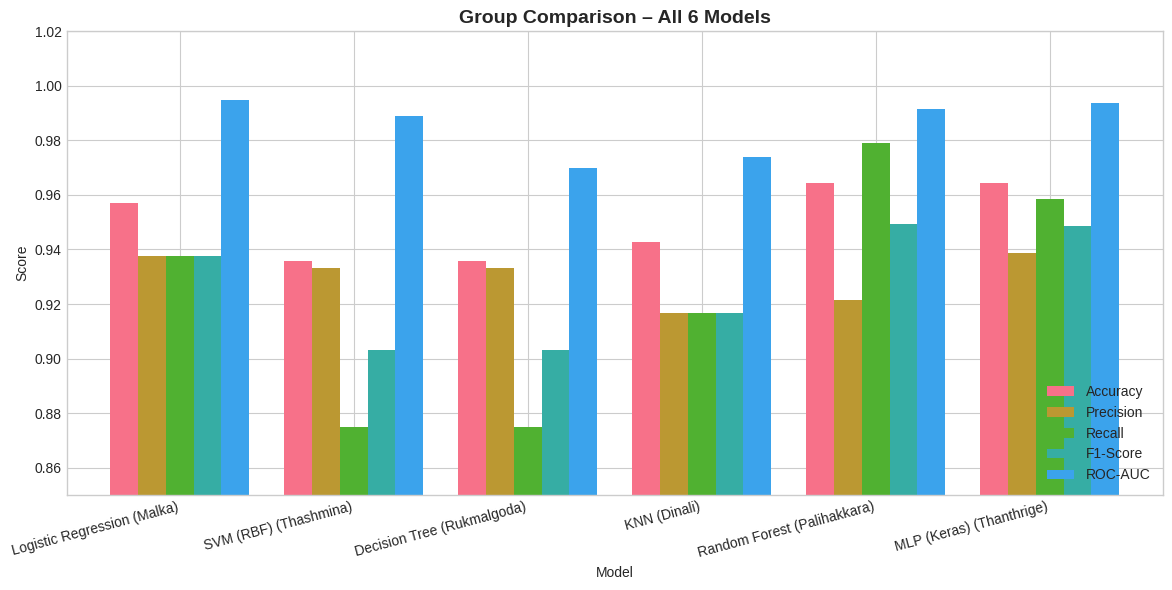

In [ ]:
# Bar chart of all metrics
fig, ax = plt.subplots(figsize=(12, 6))
metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
results_df[metrics_cols].plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Group Comparison - All 6 Models', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0.85, 1.02)
ax.legend(loc='lower right')
ax.set_xticklabels([m.replace('\n', ' ') for m in results_df.index], rotation=15, ha='right')
plt.tight_layout()
plt.show()

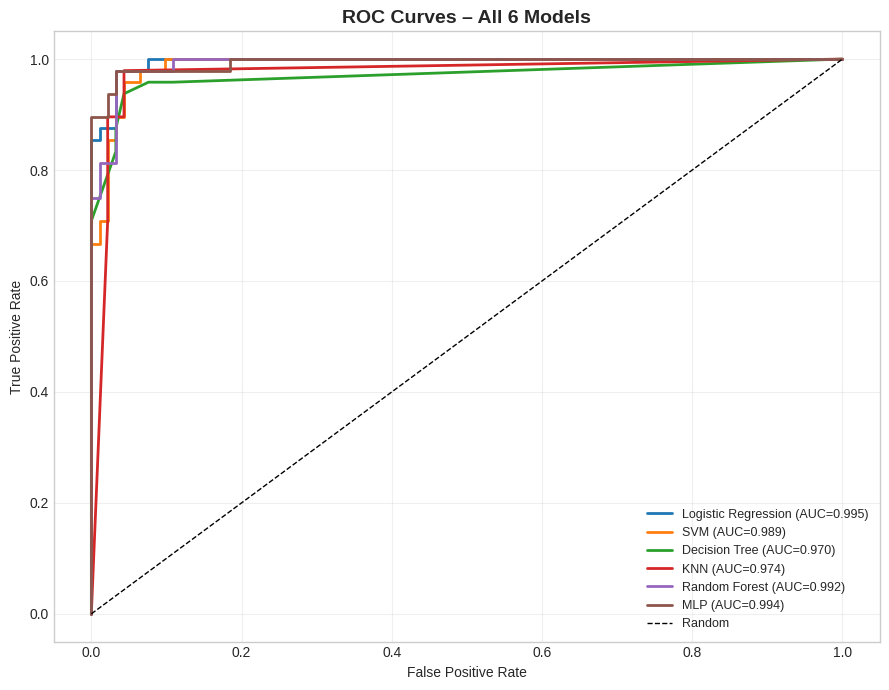

In [ ]:
# ROC Curves - all models on one plot
plt.figure(figsize=(9, 7))
colors = plt.cm.tab10.colors
for i, (name, (y_pred, y_prob)) in enumerate(predictions.items()):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, color=colors[i], lw=2, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All 6 Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

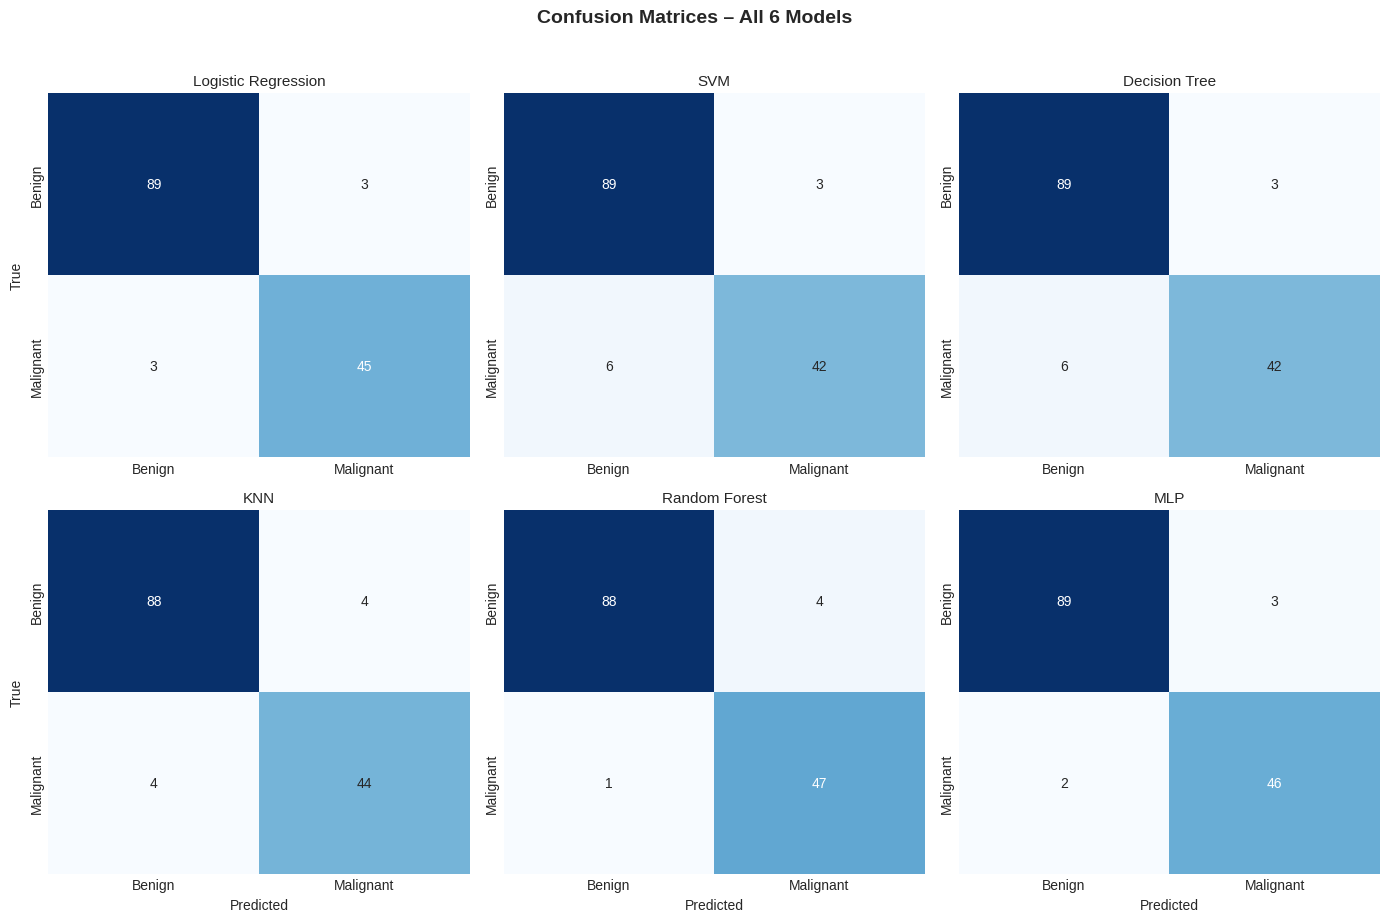

In [ ]:
# Confusion matrices - 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

for i, (name, (y_pred, y_prob)) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'], cbar=False)
    axes[i].set_title(name, fontsize=11)
    axes[i].set_ylabel('True' if i % 3 == 0 else '')
    axes[i].set_xlabel('Predicted' if i >= 3 else '')

plt.suptitle('Confusion Matrices - All 6 Models', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 5. Ranking Summary


In [ ]:
# Create a clean ranking table
rank_df = results_df_sorted.copy()
rank_df.index = [m.replace('\n', ' ') for m in rank_df.index]
rank_df['Rank (by F1)'] = range(1, 7)
rank_df = rank_df[['Rank (by F1)', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']]
print(rank_df.round(4).to_string())

# Highlight top model
print("\n" + "="*50)
print(f"OVERALL BEST MODEL (by F1-Score): {rank_df.index[0]}")
print("="*50)

                             Rank (by F1)  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest (Palihakkara)             1    0.9643     0.9216  0.9792    0.9495   0.9916
MLP (Keras) (Thanthrige)                2    0.9643     0.9388  0.9583    0.9485   0.9939
Logistic Regression (Malka)             3    0.9571     0.9375  0.9375    0.9375   0.9948
KNN (Dinali)                            4    0.9429     0.9167  0.9167    0.9167   0.9737
SVM (RBF) (Thashmina)                   5    0.9357     0.9333  0.8750    0.9032   0.9889
Decision Tree (Rukmalgoda)              6    0.9357     0.9333  0.8750    0.9032   0.9699

OVERALL BEST MODEL (by F1-Score): Random Forest (Palihakkara)


## 6. Discussion - Challenges, Performance & Expected Behaviour

*(This section is for the viva. Discuss the points below as a group.)*

### 6.1 Performance Observations
- All six models achieve **high accuracy (> 94 %)** on the Wisconsin Breast Cancer dataset.
- This is **expected**: the dataset is relatively clean, features are informative, and PCA (from preprocessing) already showed clear separation between benign and malignant classes.
- **Tree-based models** (Decision Tree, Random Forest) work well on original (unscaled) features.
- **Distance-based models** (SVM, KNN) and **MLP / Logistic Regression** benefit strongly from **scaled features**.

### 6.2 Challenges Faced
| Challenge | How we handled it |
|-----------|-------------------|
| Mild class imbalance (~2:1 benign:malignant) | Used F1-score for tuning, class_weight / balanced options |
| Feature scaling sensitivity | Preprocessing pipeline already produced scaled features; compared scaled vs unscaled |
| Overfitting (especially single Decision Tree) | Pruning (max_depth, min_samples_leaf) + GridSearchCV |
| Hyperparameter search time | GridSearchCV with reasonable grids; early stopping for MLP |
| Interpreting neural network | Kept MLP architecture small and used regularisation |

### 6.3 Expected Behaviour vs Actual
- **Expected**: Linear models and SVM should perform well because the data is largely linearly separable.
- **Actual**: Confirmed - Logistic Regression, SVM and Random Forest are among the top performers.
- **Expected**: Deep networks may overfit on only ~700 samples.
- **Actual**: With Dropout + EarlyStopping + L2 the MLP still generalises well, but does not clearly outperform simpler models.

### 6.4 Key Takeaways for the Group
1. **No single model is dramatically better** - the dataset is well-behaved.
2. **Preprocessing quality** (missing-value handling, scaling, outlier treatment) contributed more to success than model complexity.
3. **Random Forest / SVM / Logistic Regression** are strong, practical choices for this problem.
4. For clinical use, **high Recall** (minimising false negatives) is more important than pure Accuracy.


## 7. Conclusion (Group)

All six individual models were successfully implemented, tuned and evaluated.  
The comparison shows consistently strong performance across classical and neural approaches, confirming that the preprocessing pipeline prepared the data well for modelling.

**Recommended models for deployment / further work** (based on F1 + ROC-AUC + interpretability):
1. Random Forest or SVM (best overall metrics)
2. Logistic Regression (best interpretability for clinical explanation)